In [55]:
import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import joblib
import warnings
warnings.filterwarnings('ignore')

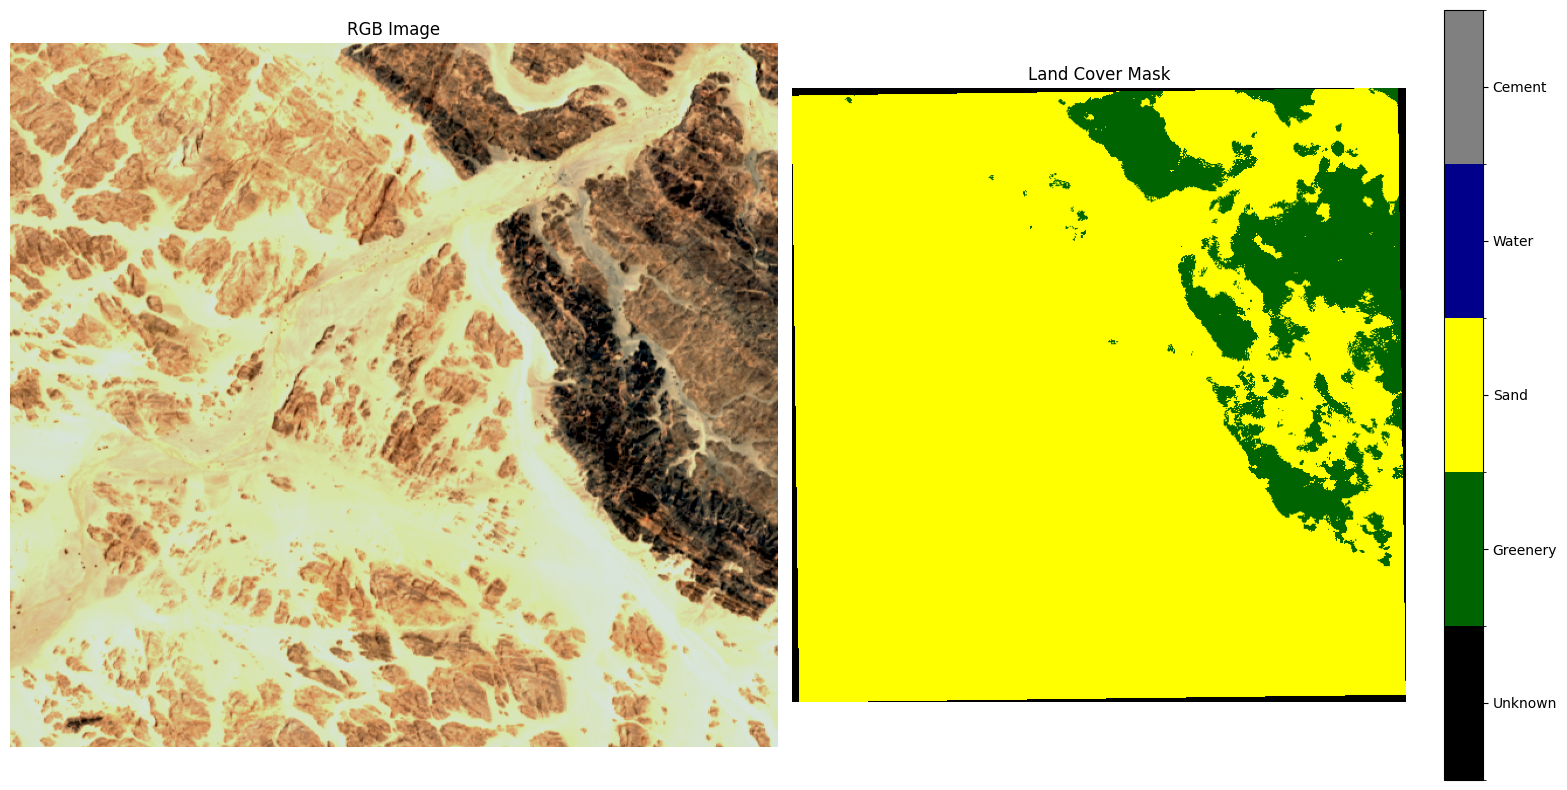

In [56]:
# this function shows the satellite rgb image next to its land cover mask
def show_rgb_and_mask(rgb_path, mask_path):
    
    with rasterio.open(rgb_path) as f:
        r = f.read(1).astype(float)
        g = f.read(2).astype(float)
        b = f.read(3).astype(float)

    # stretch each band so image looks natural
    def stretch(band):
        low  = np.percentile(band[band > 0], 1)
        high = np.percentile(band[band > 0], 99)
        band = np.clip(band, low, high)
        band = (band - low) / (high - low)
        return band

    rgb = np.stack([stretch(r), stretch(g), stretch(b)], axis=-1)
    # gamma correction and white balance to look closer to real colors
    rgb = np.power(rgb, 0.75)
    rgb[:, :, 0] *= 0.85
    rgb[:, :, 1] *= 0.90
    rgb[:, :, 2] *= 0.85
    rgb = np.clip(rgb, 0, 1)

    with rasterio.open(mask_path) as f:
        mask = f.read(1)

    colors = ['black', 'darkgreen', 'yellow', 'darkblue', 'gray']
    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    axes[0].imshow(rgb)
    axes[0].set_title('RGB Image')
    axes[0].axis('off')

    im = axes[1].imshow(mask, cmap=cmap, norm=norm)
    cbar = plt.colorbar(im, ax=axes[1], ticks=[0.5, 1.5, 2.5, 3.5, 4.5])
    cbar.ax.set_yticklabels(['Unknown', 'Greenery', 'Sand', 'Water', 'Cement'])
    axes[1].set_title('Land Cover Mask')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

BASE_SAMPLE = r'C:\Users\ALI\Desktop\sat_Project\S2_ML_Dataset_V2\WadiElGemal'
show_rgb_and_mask(BASE_SAMPLE + r'_RGB.tif', BASE_SAMPLE + r'_mask_ESRI.tif')

In [57]:
DATA_FOLDER = r'C:\Users\ALI\Desktop\sat_Project\S2_ML_Dataset_V2'
MODEL_FOLDER = r'C:\Users\ALI\Desktop\sat_Project\models'
os.makedirs(MODEL_FOLDER, exist_ok=True)

CLASS_NAMES = ['Greenery', 'Sand', 'Water', 'Cement']
CLASS_LABELS = [1, 2, 3, 4]

TRAIN_LOCS = [
    # sand / desert locations
    'BaharyaOasis', 'EasternDesert', 'FarafraOasis', 'KhargaOasis',
    'LibyanBorder', 'SinaiDesert', 'WhiteDesert',
    # greenery / farming locations
    'AssiutFarms', 'BeheiraNileDelta', 'DakhlaOasis', 'DamietaFarms',
    'HawaraFayoum', 'MiniaFarms', 'NileDelta', 'SohagFarms',
    'WadiNatrun', 'ZagazigFarms',
    # cement / urban locations
    'AlexandriaPort', 'CairoDowntown', 'CairoUniv', 'FayoumFarms',
    'GizaPlateau', 'HelwanIndustrial', 'MansouraCity', 'NaserCity',
    # water locations
    'AbuSimbelDesert', 'BardawilLake', 'GreatBitterLake', 'GulfSuez',
    'ManzalaLake', 'NasserLake', 'RedSeaHurghada', 'SaddElAly', 'SuezCanal',
]

VAL_LOCS = [
    'IconicTower', 'QattaraDepression',
    'KarnakLuxor', 'SiwaOasis',
    'PortSaidCity', 'ZagazigCity',
    'GulfAqaba', 'MariutLake',
]

TEST_LOCS = [
    'QenaFarms', 'TantaCity',
    'NileCairo', 'SuezCity',
    'WadiElGemal', 'WadiRum',
    'QarunLake', 'TimsahLake',
]

In [58]:
def compute_indices(bands):
    B2 = bands[1].astype(float)   
    B3 = bands[2].astype(float)   
    B4 = bands[3].astype(float)   
    B8 = bands[7].astype(float)   
    B8A = bands[8].astype(float)   
    B11 = bands[10].astype(float)  
    e = 1e-10  

    # vegetation index: high for green areas, low for cities and water
    NDVI = (B8 - B4) / (B8 + B4 + e)

    # detects water stress in plants
    MOISTURE = (B8A - B11) / (B8A + B11 + e)

    # water index: high for water bodies
    NDWI = (B3 - B8) / (B3 + B8 + e)

    # built-up index: high for urban/cement areas
    NDBI = (B11 - B8) / (B11 + B8 + e)

    # bare soil index: helps separate sand from cement
    BSI = ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2) + e)

    return np.stack([NDVI, MOISTURE, NDWI, NDBI, BSI], axis=0)


def load_image_and_mask(location_name):
    img_path = os.path.join(DATA_FOLDER, location_name + '_12band.tif')
    mask_path = os.path.join(DATA_FOLDER, location_name + '_mask_ESRI.tif')

    with rasterio.open(img_path) as f:
        bands = f.read().astype(np.float32)

    with rasterio.open(mask_path) as f:
        mask = f.read(1)

    # make sure image and mask have same size as GEE sometimes exports slightly different
    H = min(bands.shape[1], mask.shape[0])
    W = min(bands.shape[2], mask.shape[1])
    bands = bands[:, :H, :W]
    mask = mask[:H, :W]

    # normalize bands: Sentinel-2 values go from 0 to 10000
    # we divide by 10000 so all values are between 0 and 1
    bands = bands / 10000.0
    bands = np.clip(bands, 0, 1)

    # replace any NaN or invalid values with 0
    # NaN values come from cloud-masked pixels in the GEE export
    bands = np.nan_to_num(bands, nan=0.0, posinf=0.0, neginf=0.0)

    # compute the 5 spectral indices
    indices = compute_indices(bands)
    indices = np.nan_to_num(indices, nan=0.0, posinf=0.0, neginf=0.0)

    # combine raw bands + indices = 17 features per pixel
    features = np.concatenate([bands, indices], axis=0)
    return features, mask


def get_pixels_from_locations(location_list):
    all_X = []
    all_y = []

    for loc in location_list:
        try:
            features, mask = load_image_and_mask(loc)

            # reshape from (17, H, W) to (H*W, 17) so each row is one pixel
            num_features = features.shape[0]
            X = features.reshape(num_features, -1).T
            y = mask.flatten()

            # keep only labeled pixels :remove unknown class (0) and border areas
            labeled = y > 0
            X = X[labeled]
            y = y[labeled]

            # remove any pixel that still has NaN in its features
            clean = ~np.isnan(X).any(axis=1)
            all_X.append(X[clean])
            all_y.append(y[clean])

        except Exception as e:
            print(f'skipping {loc}: {e}')

    return np.vstack(all_X), np.concatenate(all_y)

In [59]:
print('loading training data')
X_train, y_train = get_pixels_from_locations(TRAIN_LOCS)

print('loading validation data')
X_val, y_val = get_pixels_from_locations(VAL_LOCS)

print('loading test data')
X_test, y_test = get_pixels_from_locations(TEST_LOCS)

print(f'\nTrain : {X_train.shape[0]:,} pixels, {X_train.shape[1]} features each')
print(f'Val : {X_val.shape[0]:,} pixels')
print(f'Test : {X_test.shape[0]:,} pixels')

print('\nclass distribution in training set:')
for label, name in zip(CLASS_LABELS, CLASS_NAMES):
    count = (y_train == label).sum()
    print(f'{name}: {count:,} pixels ({100*count/len(y_train):.1f}%)')

loading training data
loading validation data
loading test data

Train : 12,155,966 pixels, 17 features each
Val : 2,861,415 pixels
Test : 2,861,184 pixels

class distribution in training set:
Greenery: 3,345,681 pixels (27.5%)
Sand: 2,792,715 pixels (23.0%)
Water: 2,926,076 pixels (24.1%)
Cement: 3,091,494 pixels (25.4%)


In [60]:
def sample_equal_per_class(X, y, n=600000):
    X_out = []
    y_out = []
    for label, name in zip(CLASS_LABELS, CLASS_NAMES):
        idx = np.where(y == label)[0]
        take = min(len(idx), n)
        chosen = np.random.RandomState(42).choice(idx, take, replace=False)
        X_out.append(X[chosen])
        y_out.append(y[chosen])
        print(f'  {name}: {take:,} pixels')
    return np.vstack(X_out), np.concatenate(y_out)

print('sampling balanced training set...')
X_tr, y_tr = sample_equal_per_class(X_train, y_train, n=900000)
print(f'total training pixels: {len(X_tr):,}')

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)   
X_val_s = scaler.transform(X_val)     
X_test_s = scaler.transform(X_test)

X_tr_s = np.nan_to_num(X_tr_s, nan=0.0)
X_val_s = np.nan_to_num(X_val_s, nan=0.0)
X_test_s = np.nan_to_num(X_test_s, nan=0.0)

assert not np.isnan(X_tr_s).any(),'NaN in training data'
assert not np.isnan(X_val_s).any(),'NaN in validation data'
assert not np.isnan(X_test_s).any(),'NaN in test data'
print('normalization done')

sampling balanced training set...
  Greenery: 900,000 pixels
  Sand: 900,000 pixels
  Water: 900,000 pixels
  Cement: 900,000 pixels
total training pixels: 3,600,000
normalization done


In [61]:
# IoU per class = TP / (TP + FP + FN)
def compute_miou(true_labels, predicted_labels):
    iou_scores = {}
    for i in range(len(CLASS_LABELS)):
        c = CLASS_LABELS[i]
        tp = 0
        fp = 0
        fn = 0
        
        for j in range(len(true_labels)):
            if predicted_labels[j] == c and true_labels[j] == c:
                tp += 1
            elif predicted_labels[j] == c and true_labels[j] != c:
                fp += 1
            elif predicted_labels[j] != c and true_labels[j] == c:
                fn += 1
        iou_scores[c] = tp / (tp + fp + fn + 1e-10)
    miou = sum(iou_scores.values()) / len(iou_scores)
    return iou_scores, miou

In [62]:
class MinimumDistanceClassifier:
    def __init__(self):
        self.signatures = {}   

    def train(self, X, y):
        for label in np.unique(y):
            class_pixels = X[y == label]
            self.signatures[label] = class_pixels.mean(axis=0)
        return self
    
    ## old version take more time 
    # def classify(self, X):
    #     class_labels = list(self.signatures.keys())
    #     predictions  = np.zeros(len(X), dtype=int)

    #     # process in batches to avoid memory issues
    #     batch_size = 50000
    #     start = 0

    #     while start < len(X):
    #         end   = min(start + batch_size, len(X))
    #         batch = X[start:end]

    #         # for each pixel in this batch find the nearest class
    #         for pixel_idx in range(len(batch)):
    #             pixel = batch[pixel_idx]

    #             min_dist   = float('inf')
    #             best_class = class_labels[0]

    #             # compute distance to each class signature
    #             for c in class_labels:
    #                 signature = self.signatures[c]

    #                 # euclidean distance
    #                 diff = pixel - signature
    #                 dist = np.sqrt(np.sum(diff * diff))

    #                 if dist < min_dist:
    #                     min_dist   = dist
    #                     best_class = c
    #             predictions[start + pixel_idx] = best_class
    #         start = end
    #     return predictions

    def classify(self, X):
        labels = np.array(list(self.signatures.keys()))
        means = np.array(list(self.signatures.values()))

        batch_size = 50000
        predictions = []

        for start in range(0, len(X), batch_size):
            batch = X[start : start + batch_size]
            differences = batch[:, np.newaxis, :] - means[np.newaxis, :, :]
            distances = np.sqrt((differences ** 2).sum(axis=2))
            closest = np.argmin(distances, axis=1)
            predictions.append(labels[closest])

        return np.concatenate(predictions)

# train the classifier
print('training minimum distance classifier')
mdc = MinimumDistanceClassifier()
mdc.train(X_tr_s, y_tr)

print('\nclass signatures (mean of spectral indices after normalization):')
index_names = ['NDVI', 'Moisture', 'NDWI', 'NDBI', 'BSI']
print(f"  {'class':<12}", '  '.join(f'{n:>9}' for n in index_names))
for label, name in zip(CLASS_LABELS, CLASS_NAMES):
    sig = mdc.signatures[label][-5:]
    print(f'  {name:<12}', '  '.join(f'{v:>9.4f}' for v in sig))

joblib.dump(mdc, os.path.join(MODEL_FOLDER, 'mdc_model.pkl'))
joblib.dump(scaler, os.path.join(MODEL_FOLDER, 'scaler.pkl'))
print('\nmodel saved.')

training minimum distance classifier

class signatures (mean of spectral indices after normalization):
  class             NDVI   Moisture       NDWI       NDBI        BSI
  Greenery        1.0278     0.7412    -0.8764    -0.6257    -0.3744
  Sand           -0.2180    -0.7347    -0.1658     0.6983     0.8814
  Water          -0.9718     0.1633     1.3397    -0.3093    -0.8293
  Cement          0.1620    -0.1698    -0.2975     0.2368     0.3223

model saved.



 Validation results 


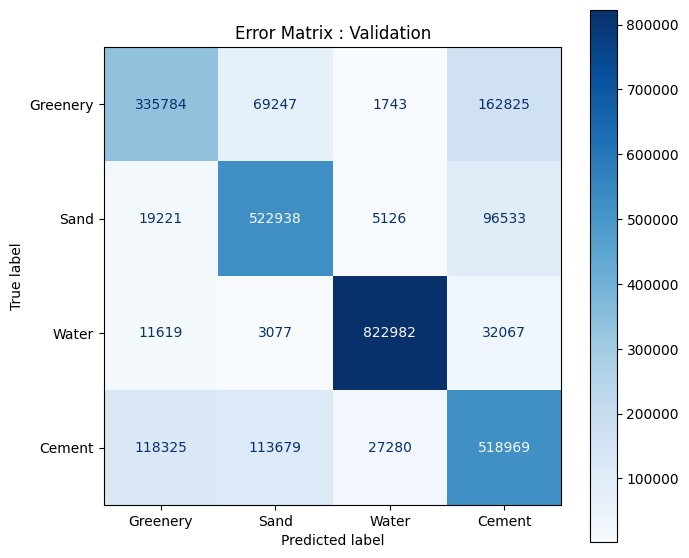

errors of omission (how many true pixels were missed):
  Greenery: 0.4105
  Sand: 0.1878
  Water: 0.0538
  Cement: 0.3332
errors of commission (how many predicted pixels were wrong):
  Greenery: 0.3076
  Sand: 0.2624
  Water: 0.0398
  Cement: 0.3596

mIoU: 0.6232
  Greenery: 0.4672
  Sand: 0.6302
  Water: 0.9105
  Cement: 0.4852
              precision    recall  f1-score   support

    Greenery       0.69      0.59      0.64    569599
        Sand       0.74      0.81      0.77    643818
       Water       0.96      0.95      0.95    869745
      Cement       0.64      0.67      0.65    778253

    accuracy                           0.77   2861415
   macro avg       0.76      0.75      0.75   2861415
weighted avg       0.77      0.77      0.77   2861415


 Test results 


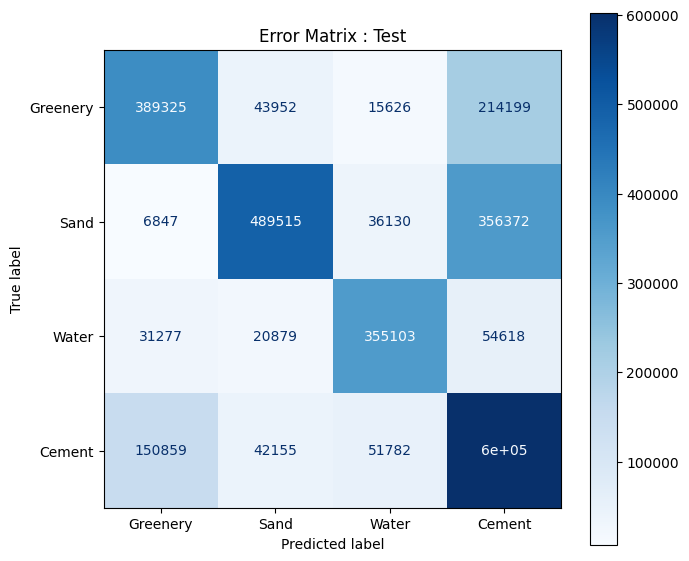

errors of omission (how many true pixels were missed):
  Greenery: 0.4129
  Sand: 0.4493
  Water: 0.2312
  Cement: 0.2889
errors of commission (how many predicted pixels were wrong):
  Greenery: 0.3268
  Sand: 0.1794
  Water: 0.2257
  Cement: 0.5092

mIoU: 0.4964
  Greenery: 0.4569
  Sand: 0.4916
  Water: 0.6280
  Cement: 0.4092
              precision    recall  f1-score   support

    Greenery       0.67      0.59      0.63    663102
        Sand       0.82      0.55      0.66    888864
       Water       0.77      0.77      0.77    461877
      Cement       0.49      0.71      0.58    847341

    accuracy                           0.64   2861184
   macro avg       0.69      0.65      0.66   2861184
weighted avg       0.68      0.64      0.65   2861184



In [63]:
def run_evaluation(split_name, X, y):
    print(f'\n {split_name} results ')

    pred = mdc.classify(X)
    cm = confusion_matrix(y, pred, labels=CLASS_LABELS)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues')
    ax.set_title(f'Error Matrix : {split_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER, f'error_matrix_{split_name}.png'), dpi=150)
    plt.show()

    print('errors of omission (how many true pixels were missed):')
    for i, name in enumerate(CLASS_NAMES):
        err = 1 - cm[i, i] / cm[i].sum()
        print(f'  {name}: {err:.4f}')

    print('errors of commission (how many predicted pixels were wrong):')
    for i, name in enumerate(CLASS_NAMES):
        err = 1 - cm[i, i] / cm[:, i].sum()
        print(f'  {name}: {err:.4f}')

    # mIoU score
    iou_dict, miou = compute_miou(y, pred)
    print(f'\nmIoU: {miou:.4f}')
    for label, name in zip(CLASS_LABELS, CLASS_NAMES):
        print(f'  {name}: {iou_dict[label]:.4f}')

    print(classification_report(y, pred, target_names=CLASS_NAMES, labels=CLASS_LABELS))
    return miou, iou_dict

val_miou, val_iou = run_evaluation('Validation', X_val_s, y_val)
test_miou, test_iou = run_evaluation('Test', X_test_s, y_test)

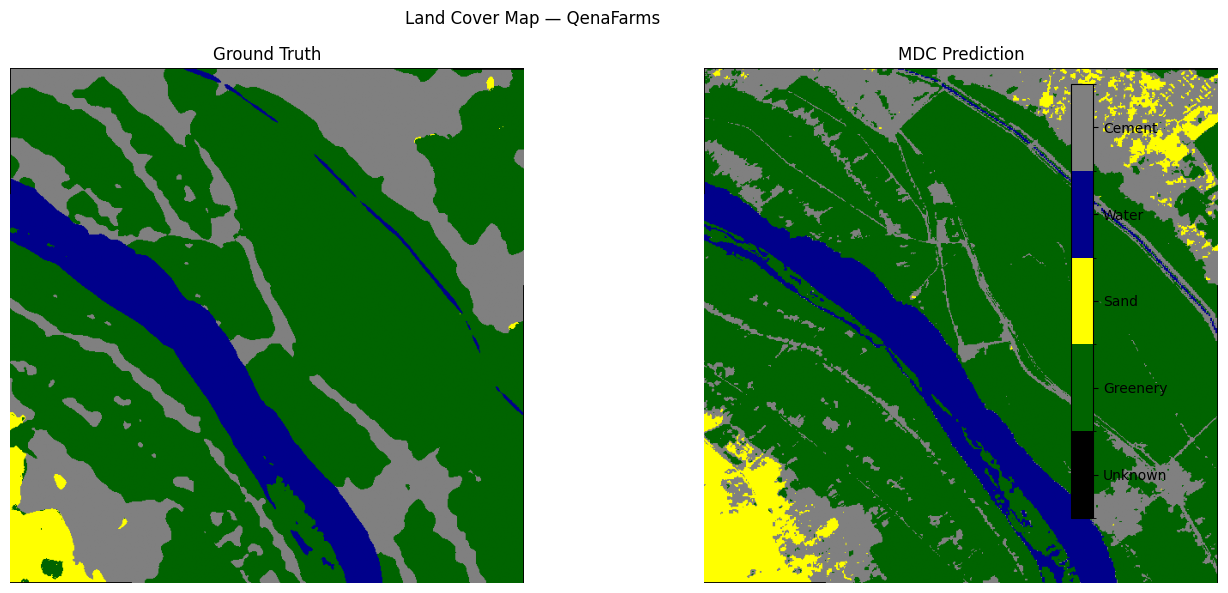

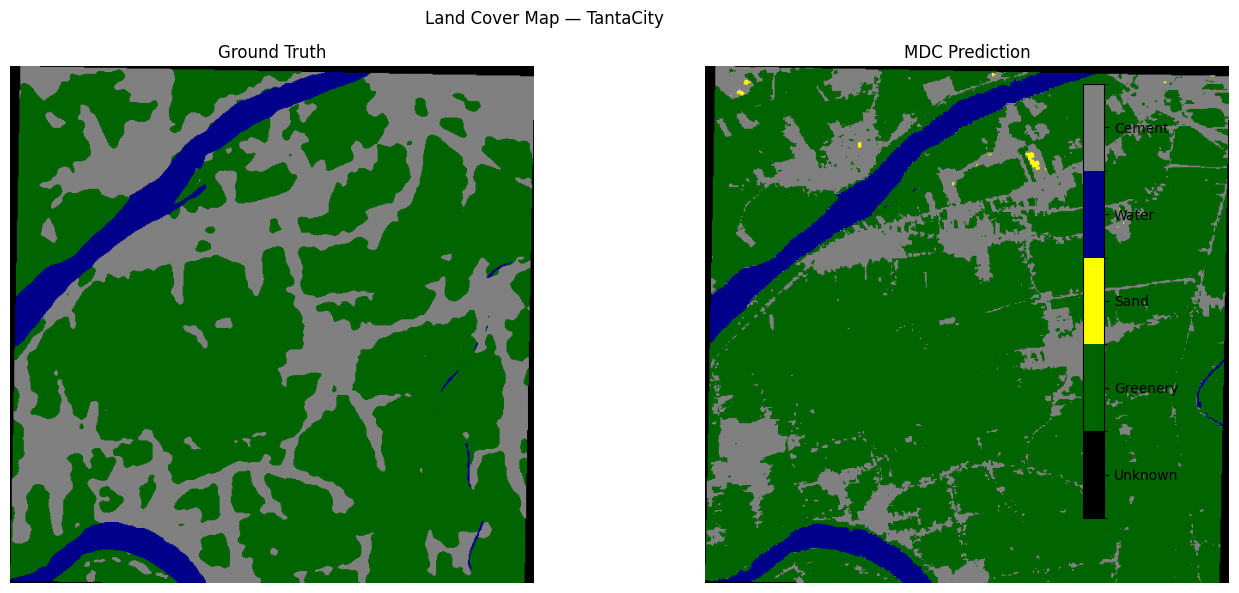

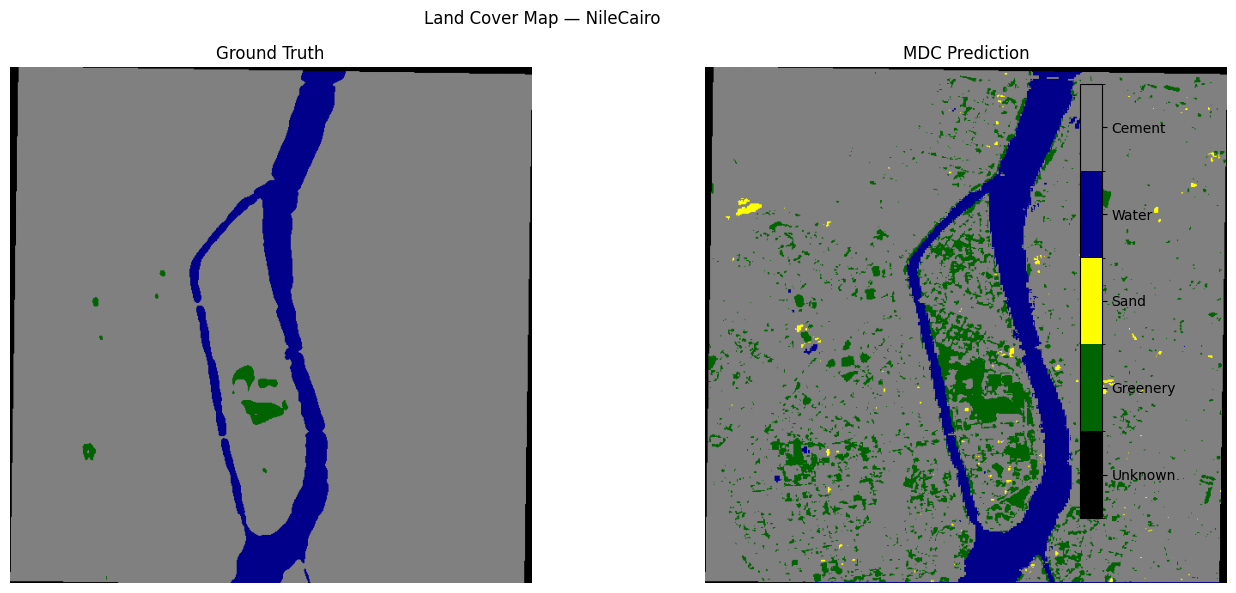

In [64]:
def make_thematic_map(location_name):
    features, mask = load_image_and_mask(location_name)
    H, W = mask.shape

    # flatten to pixels, scale, classify, then reshape back to image
    X_img = features.reshape(17, -1).T
    X_scaled= scaler.transform(X_img)
    X_scaled= np.nan_to_num(X_scaled, nan=0.0)
    pred_img= mdc.classify(X_scaled).reshape(H, W)

    # unknown border pixels stay as 0
    pred_img[mask == 0] = 0

    colors = ['black', 'darkgreen', 'yellow', 'darkblue', 'gray']
    cmap = mcolors.ListedColormap(colors)
    norm = mcolors.BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(mask, cmap=cmap, norm=norm)
    axes[0].set_title('Ground Truth')
    axes[0].axis('off')

    im = axes[1].imshow(pred_img, cmap=cmap, norm=norm)
    axes[1].set_title('MDC Prediction')
    axes[1].axis('off')

    cbar = plt.colorbar(im, ax=axes, ticks=[0.5, 1.5, 2.5, 3.5, 4.5],
                        fraction=0.02, pad=0.04)
    cbar.ax.set_yticklabels(['Unknown', 'Greenery', 'Sand', 'Water', 'Cement'])

    plt.suptitle(f'Land Cover Map — {location_name}')
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_FOLDER, f'{location_name}_prediction.png'), dpi=150)
    plt.show()

for loc in TEST_LOCS[:3]:
    make_thematic_map(loc)